In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
import rioxarray as rxr
import geopandas as gpd
from pathlib import Path
from tqdm.auto import tqdm
import torch
import yaml

from s2flow.engine.sampling import (
    EulerSampler,
    MidpointSampler,
    DDPMSampler,
    DDIMSampler,
    GANSampler,
    RegressionSampler,
)
from s2flow.models import UNetTensorWrapper, RRDBNet

font_path = '/home/dhester/.fonts/InterVariable.ttf'
font_manager.fontManager.addfont(font_path)
prop = font_manager.FontProperties(fname=font_path)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

plt.rcParams.update({
    'mathtext.fontset': 'stix',
    'mathtext.default': 'it',
})

In [3]:
img_path_dicts = {
    "sentinel2": Path("/home/dhester/s2flow/data/s2flow-s2naip/sentinel2"),
    "naip": Path("/home/dhester/s2flow/data/s2flow-s2naip/naip"),
}

sample_ids = [
    # "000139",
    # "000619",
    "001099",
    "228779", # "002019",
    # "003159",
    "229199", # "004799",
    # "005059",
    "004799",
    "229039", # "008119",
    "008359",
]

# sample_ids =[
#     '095222',
#     '139008',
#     '149308',
#     '210838',
#     '037717',
#     '042005'
# ]

In [5]:
device = torch.device('cpu')
print(f"Using device: {device}")

def sampler_config(num_steps=1):
    return {
        'device': device,
        'hyperparameters': {'use_amp': device.type != 'cpu'},
        'sampling': {'num_steps': num_steps},
    }


print("Loading flow matching model")
fm_model_config = yaml.safe_load(open('../logs/s2flow_sr_train/config.yaml'))
fm_model = UNetTensorWrapper(fm_model_config['sr_model'])
fm_model.load_state_dict(torch.load('../runs/s2flow_sr_train/model.pt', map_location='cpu'), strict=False)
fm_model.to(device)

euler_1 = EulerSampler(sampler_config(1), model=fm_model)
midpoint_20 = MidpointSampler(sampler_config(20), model=fm_model)

print("Loading diffusion model")
ddpm_model = UNetTensorWrapper(fm_model_config['sr_model'])
ddpm_model.load_state_dict(torch.load('../runs/s2flow_sr_train_ddpm/model.pt', map_location='cpu'), strict=False)
ddpm_model.to(device)
ddpm_sampler = DDPMSampler(sampler_config(100), model=ddpm_model)
ddim_sampler = DDIMSampler(sampler_config(100), model=ddpm_model)

print("Loading regression model")
regression_model_config = yaml.safe_load(open('../logs/s2flow_sr_train_regression/config.yaml'))
regression_model = UNetTensorWrapper(regression_model_config['sr_model'])
regression_model.load_state_dict(
    torch.load('../runs/s2flow_sr_train_regression/model.pt', map_location='cpu'),
    strict=False,
)
regression_model.to(device).eval()
regression_sampler = RegressionSampler(
    sampler_config(1),
    model=regression_model,
)

print("Loading GAN model")
gan_model_config = yaml.safe_load(open('../logs/s2flow_realesrgan/config.yaml'))
gan_model = RRDBNet(gan_model_config['sr_model'])
gan_model.load_state_dict(
    torch.load('../runs/s2flow_realesrgan/model.pt', map_location='cpu'),
    strict=False,
)
gan_model.to(device).eval()
gan_sampler = GANSampler(sampler_config(1), model=gan_model)

print("Loading NAIP and Sentinel-2 images")
naip_img = []
s2_img = []
for i, sample_id in tqdm(enumerate(sample_ids)):
    naip_img.append(rxr.open_rasterio(img_path_dicts['naip'] / f"{sample_id}.tif"))
    s2_img.append(rxr.open_rasterio(img_path_dicts['sentinel2'] / f"{sample_id}.tif"))

print("Preprocessing images")
naip_img = np.stack(naip_img)
s2_img = np.stack(s2_img)

s2_img_scaled = (s2_img / 10000.0) * 2.0 - 1.0
s2_img_scaled_tensor = torch.from_numpy(s2_img_scaled).float().to(device)

with torch.no_grad():
    print(f"Sampling with Euler (T=1)")
    euler_1_img_tensor = euler_1.sample(s2_img_scaled_tensor)
    print(f"Sampling with Midpoint (T=20)")
    midpoint_20_img_tensor = midpoint_20.sample(s2_img_scaled_tensor)
    print(f"Sampling with DDPM (T=100)")
    ddpm_img_tensor = ddpm_sampler.sample(s2_img_scaled_tensor)
    print(f"Sampling with DDIM (T=100)")
    ddim_img_tensor = ddim_sampler.sample(s2_img_scaled_tensor)
    print(f"Sampling with Regression")
    regression_img_tensor = regression_sampler.sample(s2_img_scaled_tensor)
    print(f"Sampling with Real-ESRGAN")
    gan_img_tensor = gan_sampler.sample(s2_img_scaled_tensor)

# downsample to the original Sentinel-2 resolution
print("Downsampling to the original Sentinel-2 resolution")
s2_img_down_tensor = torch.nn.functional.interpolate(
    s2_img_scaled_tensor,
    scale_factor=0.25,
    mode='bicubic',
    align_corners=False,
)

Using device: cpu
Loading flow matching model
Loading diffusion model
Loading regression model
Loading GAN model
Loading NAIP and Sentinel-2 images


0it [00:00, ?it/s]

Preprocessing images
Sampling with Euler (T=1)


Sampling with Midpoint (T=20)


Sampling with DDPM (T=100)


Sampling with DDIM (T=100)


Sampling with Regression
Sampling with Real-ESRGAN
Downsampling to the original Sentinel-2 resolution


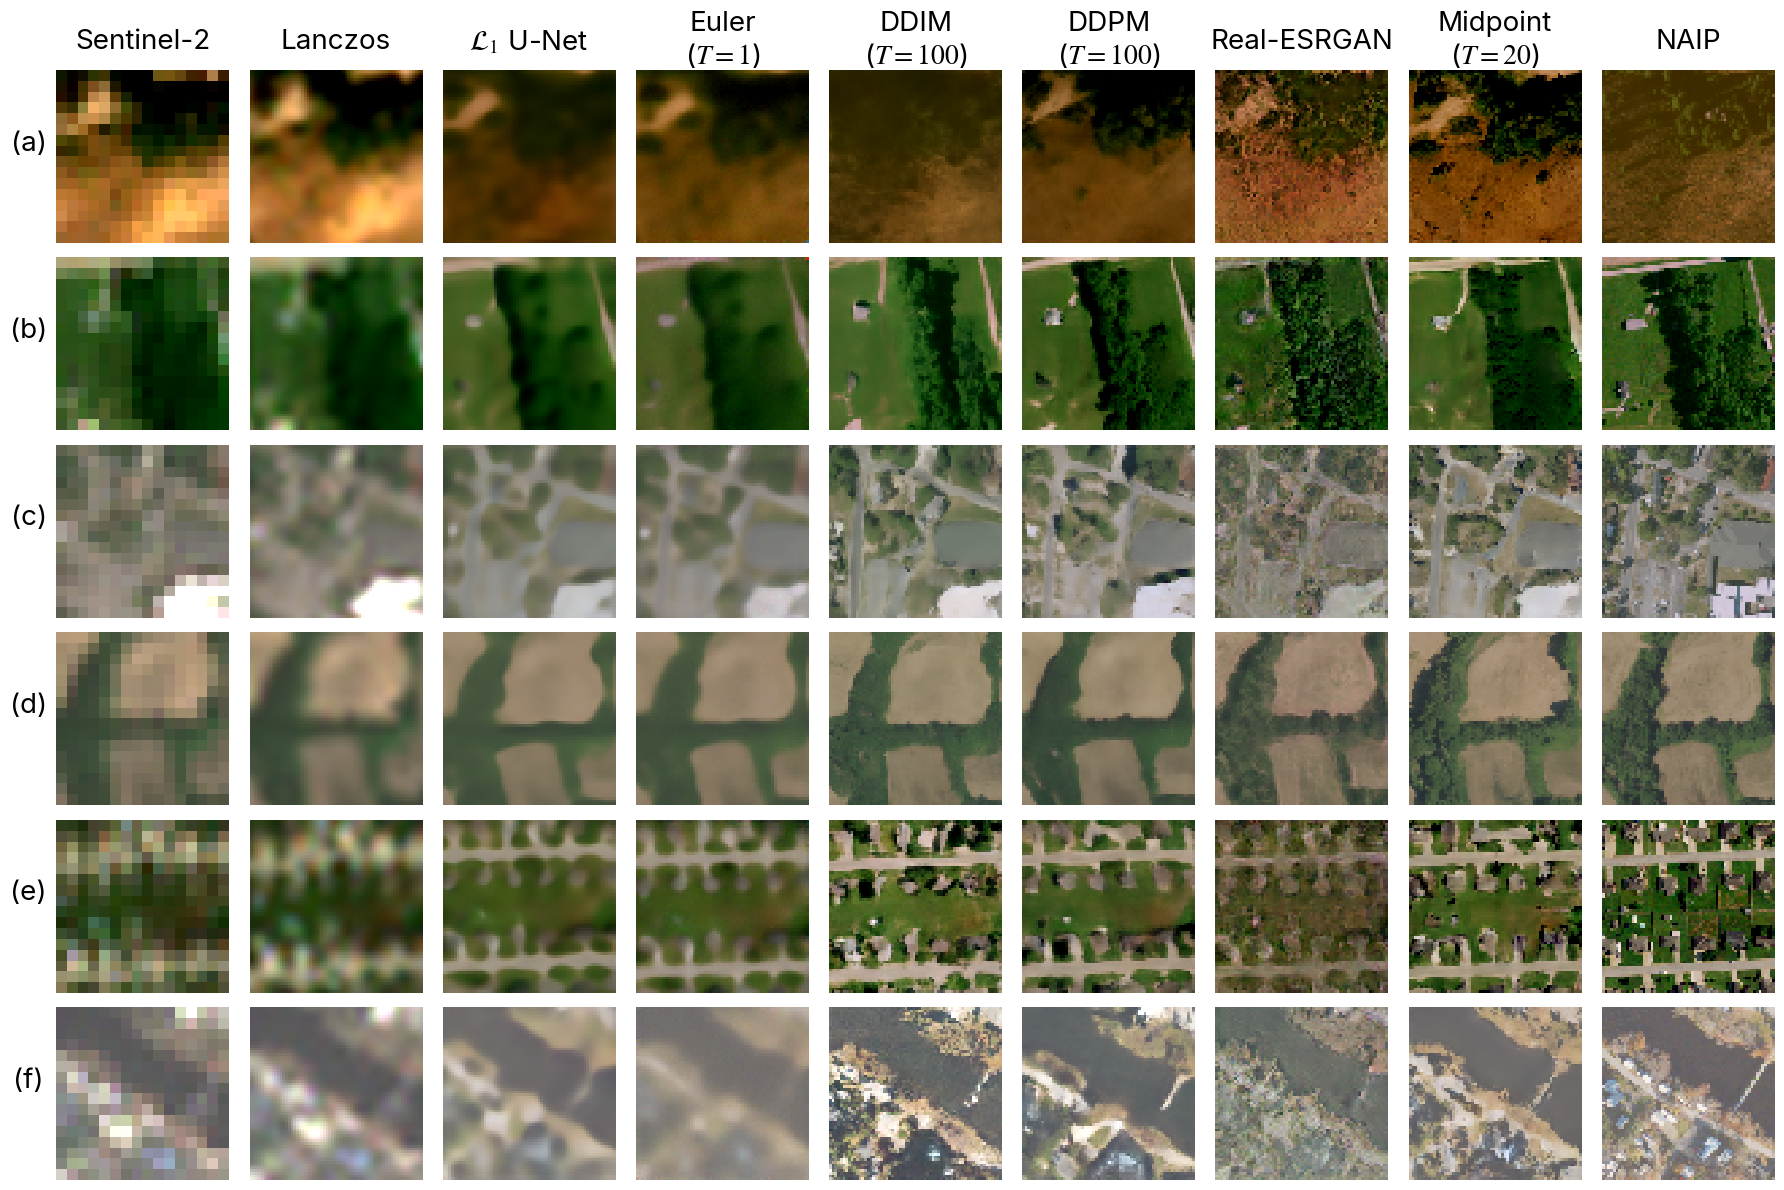

In [6]:
zoom_level = 4  # e.g. 2, 3, or 4

sample_settings = {
    # Keep gain and crop location associated with sample IDs, not their positions.
    "001099": {"gain": 4.0, "position": "bottom_right"},
    "228779": {"gain": 4.0, "position": "top_right"},
    "229199": {"gain": 2.0, "position": "top_center"},
    "004799": {"gain": 2.0, "position": "center"},
    "229039": {"gain": 3.5, "position": "top_right"},
    "008359": {"gain": 3.0, "position": "bottom_left"},
}

assert set(sample_ids) == set(sample_settings), (
    f"Sample IDs and plot settings differ: "
    f"missing={set(sample_ids) - set(sample_settings)}, "
    f"unused={set(sample_settings) - set(sample_ids)}"
)
assert zoom_level >= 1, "zoom_level must be at least 1"

def make_zoom_slices(image_shape, level, position):
    height, width = image_shape
    crop_height = max(1, round(height / level))
    crop_width = max(1, round(width / level))
    crop_height = min(crop_height, height)
    crop_width = min(crop_width, width)
    center_y = (height - crop_height) // 2
    center_x = (width - crop_width) // 2

    positions = {
        "top_left": (0, 0),
        "top_center": (0, center_x),
        "center_top": (0, center_x),
        "top_right": (0, width - crop_width),
        "center_left": (center_y, 0),
        "center": (center_y, center_x),
        "center_right": (center_y, width - crop_width),
        "bottom_left": (height - crop_height, 0),
        "bottom_center": (height - crop_height, center_x),
        "center_bottom": (height - crop_height, center_x),
        "bottom_right": (height - crop_height, width - crop_width),
    }
    if position not in positions:
        raise ValueError(f"Unknown zoom position: {position}")

    y_start, x_start = positions[position]
    return (
        slice(y_start, y_start + crop_height),
        slice(x_start, x_start + crop_width),
    )

gamma = 0.8  # <1 brightens, >1 darkens
contrast = 1.5  # >1 increases contrast around mid-gray

def enhance(img):
    img = img ** gamma
    return ((img - 0.5) * contrast + 0.5).clip(0, 1)

size = 2
rows = len(sample_ids)
cols = 9
fig, ax = plt.subplots(rows, cols, figsize=(size*cols, size*rows))

full_height, full_width = s2_img_scaled_tensor.shape[-2:]
down_height, down_width = s2_img_down_tensor.shape[-2:]

for i, sample_id in enumerate(sample_ids):
    settings = sample_settings[sample_id]
    gain = settings["gain"]
    zoom = make_zoom_slices(
        s2_img_scaled_tensor.shape[-2:], zoom_level, settings["position"]
    )
    
    s2_img_i = s2_img_scaled_tensor[i].float().cpu().numpy().transpose(1, 2, 0)[..., :3]
    s2_img_down_i = s2_img_down_tensor[i].float().cpu().numpy().transpose(1, 2, 0)[..., :3]
    naip_img_i = naip_img[i].transpose(1, 2, 0)[..., :3]
    
    regression_img_i = regression_img_tensor[i].float().cpu().numpy().transpose(1, 2, 0)[..., :3]
    euler_1_img_i = euler_1_img_tensor[i].float().cpu().numpy().transpose(1, 2, 0)[..., :3]
    midpoint_20_img_i = midpoint_20_img_tensor[i].float().cpu().numpy().transpose(1, 2, 0)[..., :3]
    ddpm_img_i = ddpm_img_tensor[i].float().cpu().numpy().transpose(1, 2, 0)[..., :3]
    ddim_img_i = ddim_img_tensor[i].float().cpu().numpy().transpose(1, 2, 0)[..., :3]
    gan_img_i = gan_img_tensor[i].float().cpu().numpy().transpose(1, 2, 0)[..., :3]
    
    # scale model outputs from [-1, 1] to [0, 1]
    s2_img_i = (((s2_img_i + 1.0) / 2.0) * gain).clip(0, 1)
    s2_img_down_i = (((s2_img_down_i + 1.0) / 2.0) * gain).clip(0, 1)
    regression_img_i = (((regression_img_i + 1.0) / 2.0) * gain).clip(0, 1)
    euler_1_img_i = (((euler_1_img_i + 1.0) / 2.0) * gain).clip(0, 1)
    ddim_img_i = (((ddim_img_i + 1.0) / 2.0) * gain).clip(0, 1)
    ddpm_img_i = (((ddpm_img_i + 1.0) / 2.0) * gain).clip(0, 1)
    gan_img_i = (((gan_img_i + 1.0) / 2.0) * gain).clip(0, 1)
    midpoint_20_img_i = (((midpoint_20_img_i + 1.0) / 2.0) * gain).clip(0, 1)
    naip_img_i = ((naip_img_i / 10000.0) * gain).clip(0, 1)
    
    (s2_img_i, s2_img_down_i, regression_img_i, euler_1_img_i, ddim_img_i,
     ddpm_img_i, gan_img_i, midpoint_20_img_i, naip_img_i) = map(enhance, (
        s2_img_i, s2_img_down_i, regression_img_i, euler_1_img_i, ddim_img_i,
        ddpm_img_i, gan_img_i, midpoint_20_img_i, naip_img_i))
    
    down_zoom = (
        slice(zoom[0].start * down_height // full_height,
              zoom[0].stop * down_height // full_height),
        slice(zoom[1].start * down_width // full_width,
              zoom[1].stop * down_width // full_width),
    )
    
    ax[i, 0].imshow(s2_img_down_i[down_zoom], interpolation="nearest")
    ax[i, 1].imshow(s2_img_i[zoom], interpolation="nearest")
    ax[i, 2].imshow(regression_img_i[zoom], interpolation="nearest")
    ax[i, 3].imshow(euler_1_img_i[zoom], interpolation="nearest")
    ax[i, 4].imshow(ddim_img_i[zoom], interpolation="nearest")
    ax[i, 5].imshow(ddpm_img_i[zoom], interpolation="nearest")
    ax[i, 6].imshow(gan_img_i[zoom], interpolation="nearest")
    ax[i, 7].imshow(midpoint_20_img_i[zoom], interpolation="nearest")
    ax[i, 8].imshow(naip_img_i[zoom], interpolation="nearest")
    
    for j in range(cols):
        ax[i, j].set_xticks([])
        ax[i, j].set_yticks([])
        # remove border
        ax[i, j].spines[:].set_visible(False)

fontsize = 20
single_line_pad = 20  # raise single-line titles by about half a text line
ax[0, 0].set_title('Sentinel-2', fontsize=fontsize, loc='center', va='center', pad=single_line_pad)
ax[0, 1].set_title('Lanczos', fontsize=fontsize, loc='center', va='center', pad=single_line_pad)
ax[0, 2].set_title(r'$\mathcal{L}_1$ U-Net', fontsize=fontsize, loc='center', va='center', pad=single_line_pad)
ax[0, 3].set_title('Euler\n($T=1$)', fontsize=fontsize, loc='center', va='center')
ax[0, 4].set_title('DDIM\n($T=100$)', fontsize=fontsize, loc='center', va='center')
ax[0, 5].set_title('DDPM\n($T=100$)', fontsize=fontsize, loc='center', va='center')
ax[0, 6].set_title('Real-ESRGAN', fontsize=fontsize, loc='center', va='center', pad=single_line_pad)
ax[0, 7].set_title('Midpoint\n($T=20$)', fontsize=fontsize, loc='center', va='center')
ax[0, 8].set_title('NAIP', fontsize=fontsize, loc='center', va='center', pad=single_line_pad)

# label rows
ax[0, 0].set_ylabel('(a)', fontsize=fontsize, rotation=0, labelpad=fontsize)
ax[1, 0].set_ylabel('(b)', fontsize=fontsize, rotation=0, labelpad=fontsize)
ax[2, 0].set_ylabel('(c)', fontsize=fontsize, rotation=0, labelpad=fontsize)
ax[3, 0].set_ylabel('(d)', fontsize=fontsize, rotation=0, labelpad=fontsize)
ax[4, 0].set_ylabel('(e)', fontsize=fontsize, rotation=0, labelpad=fontsize)
ax[5, 0].set_ylabel('(f)', fontsize=fontsize, rotation=0, labelpad=fontsize)

fig.tight_layout()

out_path = Path("../figures/s2flow_sr_model_comparison_2")
out_path.mkdir(parents=True, exist_ok=True)
for file_ext in ['png', 'pdf']:
    plt.savefig(out_path / f's2flow_sr_model_comparison.{file_ext}', dpi=300)